# 04 · Categorical encoding

[Guide](../README.md) | [Previous](03_Missing_Values_and_Scaling.ipynb) | [Next](05_Feature_Engineering.ipynb)

## 1. What problem are we solving?

How can a model use labels such as Home, Away, and Neutral?

## 2. Why does it matter?

Most estimators need numerical inputs; arbitrary numbers can suggest a false order.

## 3. Key concepts

| Term | Simple meaning |
|---|---|
| One-hot | Make a separate yes/no input for each category; do not invent an order. |
| Grouped one-hot | Share one input among infrequent categories to reduce the number of columns. |
| Ordinal encoding | Give categories integer codes. This is compact, but a model may treat the codes as an order. |
| Target encoding | Replace a category with a training estimate of its goal rate; rare groups may need smoothing toward the overall rate. |
| Cross-fitting | Encode each training group using rates learned from other groups, excluding its own answers. New rows use training-only rates. |
| Pipeline notation | `clone` copies unfitted settings; `step__setting` changes one pipeline setting. Earlier steps stay fixed during a comparison. |

## 4. Intuitive example

For `Home`, one-hot could be `[Home=1, Away=0, Neutral=0]`; ordinal coding could give Home=0, Away=1, Neutral=2, an order that is not meaningful here. A 5%-frequency category can enter an infrequent group under a 10% cutoff. For target encoding, if six of ten OTHER-fold Home kicks scored, the unsmoothed code is 0.60; the row's own answer must not contribute.

## 5. Methods to compare

| Method | Representation | Trade-off |
|---|---|---|
| One-hot | One yes/no input per category | No artificial order; adds columns |
| Grouped one-hot | Pool categories below 10% frequency | Fewer columns; loses rare-category detail |
| Ordinal codes | Integers such as 0, 1, 2 | Compact; implies an order that may be false |
| Cross-fitted target rates | Goal rates from other training groups | Compact; extra splits prevent own-answer leakage |

`TargetEncoder.fit_transform` cross-fits inside each fitting fold. Never calculate target rates from the full labeled file before splitting.

## 6. What we retained from previous notebooks

| Earlier decision | Choice used here |
|---|---|
| Missing | Drop incomplete training rows |
| Scaling | Robust scaling |

## 7. Setup

**Reusable setup — run this cell, then skip to the lesson.** You do not need to study all these lines now: they load the data and rebuild earlier steps so this notebook works on its own. Revisit the earlier lessons for explanations.

Change `DATA_DIR` for your runtime. The cell starts collapsed where the editor supports it; GitHub may show it expanded. `X` contains inputs; `y` contains known answers. Learned preparation stays inside training folds.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 3)

# Change this one folder on Kaggle or Colab (see the guide).
DATA_DIR = "../data"
train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
print("Train:", train.shape, "Test:", test.shape)

# Split train.csv: 80% for training, 20% for a separate validation check.
training_data, validation_data = train_test_split(
    train, test_size=0.20, stratify=train["is_scored"], random_state=2026
)
training_data = training_data.reset_index(drop=True)

# IDs identify rows; they do not describe how a penalty was taken.
id_columns = ["id", "kicker_id", "keeper_id", "match_id"]
X = training_data.drop(columns=id_columns + ["is_scored"])
y = training_data["is_scored"]

from sklearn.base import clone
from sklearn.compose import make_column_selector
from sklearn.preprocessing import OrdinalEncoder, RobustScaler, TargetEncoder
from imblearn import FunctionSampler
from imblearn.pipeline import Pipeline

def remove_incomplete_rows(X, y):
    keep = ~X.isna().any(axis=1)
    return X.loc[keep], y[keep]

numbers = Pipeline([("fill", SimpleImputer(strategy='median')), ("scale", RobustScaler())])
categories = Pipeline([
    ("fill", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocess = ColumnTransformer([
    ("numbers", numbers, make_column_selector(dtype_include="number")),
    ("categories", categories, make_column_selector(dtype_exclude="number")),
])

pipeline = Pipeline([
    ("missing_rows", FunctionSampler(func=remove_incomplete_rows, validate=False)),
    ("prepare", preprocess),
    ("model", LogisticRegression(solver="liblinear", max_iter=1000, random_state=42)),
])

# Each fold trains on two parts and predicts the third, unseen part.
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

def compare(models, X, y):
    rows = []
    for name, model in models.items():
        scores = cross_validate(model, X, y, cv=cv, scoring=["f1", "accuracy", "roc_auc"])
        rows.append([name, scores["test_f1"].mean(), scores["test_f1"].std(),
                     scores["test_accuracy"].mean(), scores["test_roc_auc"].mean()])
    columns = ["method", "F1", "F1 spread", "accuracy", "ROC-AUC"]
    return pd.DataFrame(rows, columns=columns).sort_values("F1", ascending=False)

Train: (20000, 20) Test: (6000, 19)


## 8. Experiments

Run the topic-specific steps below. Saved experimental outputs are retained from the earlier runs; regrouping setup does not create a new evaluation.

In [10]:
models = {
    "One-hot": clone(pipeline),
    "Grouped one-hot": clone(pipeline).set_params(prepare__categories__encode=OneHotEncoder(handle_unknown="ignore", min_frequency=0.1, sparse_output=False)),
    "Ordinal codes": clone(pipeline).set_params(prepare__categories__encode=OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
    "Cross-fitted target rates": clone(pipeline).set_params(prepare__categories__encode=TargetEncoder(target_type="binary", cv=3, shuffle=True, random_state=42)),
}

,method,F1,F1 spread,accuracy,ROC-AUC
0,One-hot,0.852,2.800e-03,0.867,0.941
1,Grouped one-hot,0.852,2.500e-03,0.867,0.941
3,Cross-fitted target rates,0.845,5.000e-04,0.861,0.938
2,Ordinal codes,0.765,2.800e-03,0.792,0.880


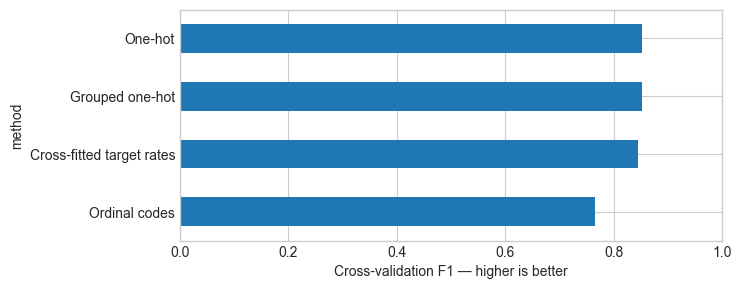

Continue with: One-hot


In [11]:
results = compare(models, X, y)
display(results.round(4))
results.set_index("method")["F1"].sort_values().plot.barh(figsize=(7, 3))
plt.xlabel("Cross-validation F1 — higher is better")
plt.xlim(0, 1)
plt.show()
print("Continue with:", results.iloc[0]["method"])

In [12]:
example = X[["home_or_away"]].head()
display(example)
display(pd.get_dummies(example, dtype=int))

,home_or_away
0,Home
1,Away
2,Home
3,Neutral
4,Home


,home_or_away_Away,home_or_away_Home,home_or_away_Neutral
0,0,1,0
1,1,0,0
2,0,1,0
3,0,0,1
4,0,1,0


**Other alternatives:** frequency encoding replaces a category with its training frequency (loses category identity);
hashing limits the number of columns (different categories may collide); binary encoding uses bit patterns
(compact, but less directly interpretable). Never calculate target rates from the full labeled table before splitting.

## 9. Results and decision

| Question | Answer |
|---|---|
| What did we compare? | One-hot, grouped one-hot, ordinal codes, and cross-fitted target encoding. |
| Which performed best? | One-hot — mean CV F1 0.8520 (rounded saved result). |
| Why did we choose it? | One-hot does not invent a category order and its extra columns are manageable here. |
| What are its limitations? | Many categories can create many columns; unseen categories need explicit handling. A different learner may prefer another representation. |
| What continues to the next notebook? | One-hot encoding, with unknown categories handled explicitly. |

## 10. Key takeaways and next step

- Category codes are a modeling choice, not numerical facts.
- Target rates need cross-fitting so a row's own answer cannot determine its code.

Next: [05 Feature Engineering](05_Feature_Engineering.ipynb).